# Part 1: Read in the data

In [67]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
DATA_DIR = Path("../data")

languages = pd.read_csv(DATA_DIR / "languages_dataset.csv")

In [26]:
# INSPECT

print(languages.head())
print(languages.shape)
print(languages.isna().sum())
print(languages.loc[languages["ISO Code"].isna()])

          Language         Family     Region  Speakers Writing System ISO Code
0           Yoruba  Indo-European      India  76000000          Latin       om
1     Southern Min  Indo-European      India  47000000          Latin       ru
2  Yue (Cantonese)      Dravidian      India  75000000     Devanagari       my
3          Spanish   Austronesian     Poland  76900000     Devanagari       it
4           Arabic  Indo-European  Worldwide  76000000         Hangul       ur
(500, 6)
Language           0
Family             0
Region             0
Speakers           0
Writing System     0
ISO Code          11
dtype: int64
              Language         Family                  Region   Speakers  \
19             Burmese        Kra-Dai  Russia, Eastern Europe   25000000   
33             Kannada   Afro-Asiatic         India, Pakistan   50000000   
52             Marathi   Austronesian                   Italy   76900000   
80              Korean    Niger-Congo                  Poland   27000000  

There are no missing values. There are 500 rows and 6 columns which means there are 500 languages represented in the data and all the data is filled for each of them (except for ISO code, but I will not use it for my analysis).

# Part 2: Modular Cleaning

In [ ]:
def clean_columns(data: pd.DataFrame) -> pd.DataFrame:
    """Get rid of spaces in the column names
    
    Parameters
    ---
    data: DataFrame
        dataset
    
    Returns
    ---
    dataframe
        dataframe of dataset with no spaces in the columns
            
    """
    data.columns = data.columns.str.replace(' ', '')
    return data


clean_columns(languages).head()

,Language,Family,Region,Speakers,WritingSystem,ISOCode
0,Yoruba,Indo-European,India,76000000,Latin,om
1,Southern Min,Indo-European,India,47000000,Latin,ru
2,Yue (Cantonese),Dravidian,India,75000000,Devanagari,my
3,Spanish,Austronesian,Poland,76900000,Devanagari,it
4,Arabic,Indo-European,Worldwide,76000000,Hangul,ur


In [ ]:
def filter_languages(data: pd.DataFrame, column:str, category:str) -> int:
    """ Sum the number of languages with certain categorical characteristics

    Parameters
    ---
    data: DataFrame
        dataset
    column: str
        column to be filtered
    category: str
        group (from the column) included in the filter
    
    Returns
    ---
    int
        number of languages in the category/group

    """
    return len(data.loc[data[column] == category])

filter_languages(languages, "Region", "Korea")

8

In [31]:
def avg_speakers(data: str) -> int:
    """Calculate the average number of speakers in an entire dataset

    Parameters
    ---
    data
        dataset

    Returns
    ---
    dataframe
        average number of speakers
        
    """
    return data["Speakers"].sum() / len(data)

avg_speakers(languages)

np.float64(98402000.0)

# Part 3: Exploratory Analysis

In [ ]:
# Question 1: How many languages of each language family are in each region?

languages.groupby(["Region", "Family"]).agg(Families=("Family", "size"), Speakers=("Speakers", "sum"))

Families    Speakers
Region                Family                             
Afghanistan, Pakistan Afro-Asiatic          1    22000000
                      Dravidian             1    32000000
                      Indo-European         6   278000000
                      Kra-Dai               2    47000000
                      Niger-Congo           1    20000000
...                                       ...         ...
Worldwide             Indo-European        13  1033000000
                      Indo-Iranian          3  1217000000
                      Niger-Congo           2   117000000
                      Sino-Tibetan          5   331000000
                      Turkic                2    75000000

[173 rows x 2 columns]

These results show which language family exist in each region. It also displays which language family is the most common in the regions by language count and by number of speakers.

In [57]:
# Question 2: How many languages use each writing system?

languages.groupby("WritingSystem")["Language"].count().sort_values(ascending = False)

WritingSystem
Latin                        203
Devanagari                    28
Perso-Arabic                  24
Arabic                        21
Chinese                       21
Simplified Chinese            20
Traditional Chinese           20
Ethiopic                      19
Cyrillic                      19
Tamil                         16
Burmese                       14
Hangul                        13
Bengali                       10
Kanji, Hiragana, Katakana     10
Shahmukhi, Gurmukhi           10
Shahmukhi, Devanagari         10
Telugu                         8
Oriya                          8
Thai                           8
Malayalam                      7
Kannada                        6
Gujarati                       5
Name: Language, dtype: int64

These results show which writing systems are the most common for languages. It displays each writing system and how many languages utilize it. 

# Part 4: Visualization

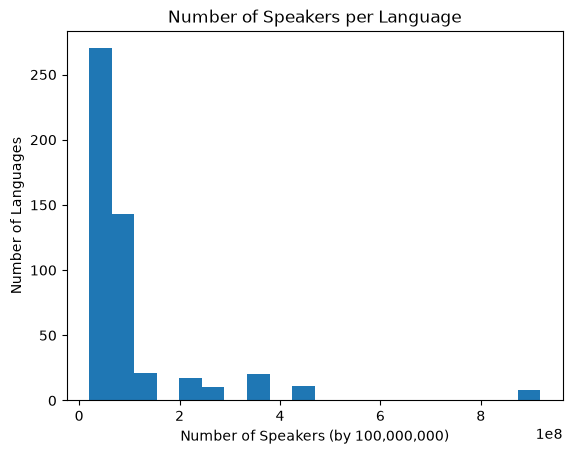

In [ ]:
# Plot 1: distribution

plt.hist(languages["Speakers"], bins = 20)
plt.xlabel("Number of Speakers (by 100,000,000)")
plt.ylabel("Number of Languages")
plt.title("Number of Speakers per Language")
plt.show()

In [ ]:
# Plot 2: comparison across groups

In [ ]:
# Plot 3: relationship

num_speakers = languages.groupby("Region")["Speakers"].sum().reset_index()
num_langs = languages.groupby("Region")["Language"].size().reset_index()
new_lang_data = num_speakers.merge(num_langs, on="Region")

sns.scatterplot(data = languages, x = "col_name", y = "col_name")
plt.show()

# number of speakers in a region vs number of languages in the region